In [55]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

In [20]:
def load_events(filename, well_no = 0, recording_no = 0):
    with h5py.File(filename, "r") as h5_file:
        h5_object = h5_file['wells']['well{0:0>3}'.format(well_no)]['rec{0:0>4}'.format(recording_no)]

        events = h5_object['events']
        events_arr= np.array(events)
        events_dataset = pd.DataFrame(events_arr)
    
    events_dataset["frameno_adjusted"] = events_dataset["frameno"] - events_dataset.loc[0, "frameno"]
    events_dataset["eventmessage_decoded"] = events_dataset["eventmessage"].apply(lambda x: x.decode("utf8"))
    events_dataset.loc[1100, "eventmessage_decoded"]

    return events_dataset

In [21]:
filename = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/7-9 mouse_1d_test/1/well4/20_min_well_4.raw.h5"
well = 4
events = load_events(filename, well)
events


,frameno,eventtype,eventid,eventmessage,frameno_adjusted,eventmessage_decoded
0,123146335,1,1,"b'{""before_training"":""1""}\n'",0,"{""before_training"":""1""}\n"
1,123146386,1,7,"b'{""map"":""100010"",""moveto"":""3"",""object"":""0""}\n'",51,"{""map"":""100010"",""moveto"":""3"",""object"":""0""}\n"
2,123176523,1,6,"b'{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n'",30188,"{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n"
3,123496862,1,5,"b'{""map"":""100010"",""moveto"":""1"",""object"":""0""}\n'",350527,"{""map"":""100010"",""moveto"":""1"",""object"":""0""}\n"
4,123876766,1,6,"b'{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n'",730431,"{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n"
...,...,...,...,...,...,...
2282,147121648,1,104,"b'{""start_stimulation"":""loc0_distance""}\n'",23975313,"{""start_stimulation"":""loc0_distance""}\n"
2283,147132176,1,105,"b'{""end_stimulation"":""loc0_distance""}\n'",23985841,"{""end_stimulation"":""loc0_distance""}\n"
2284,147132226,1,104,"b'{""start_stimulation"":""loc0_distance""}\n'",23985891,"{""start_stimulation"":""loc0_distance""}\n"
2285,147142754,1,105,"b'{""end_stimulation"":""loc0_distance""}\n'",23996419,"{""end_stimulation"":""loc0_distance""}\n"


In [22]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "position"])

current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        print(numbers)
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        print("switch to train")
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "position"])


train_movement_df = movement_df
display(train_movement_df)
display(pre_train_movement_df)


world


[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 4, 1]
[100010, 3, 0]
switch to train
[100010, 2, 0]
[100010, 3, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 

,frameno,position
0,12021300,2
1,12382516,3
2,12881515,4
3,13711504,5
4,13870799,0
5,14456373,1
6,14615688,0
7,15180064,1
8,16082800,0
9,16402914,5


,frameno,position
0,51,3
1,30188,2
2,350527,1
3,730431,2
4,1816228,3
5,2397148,4
6,2762550,5
7,3308487,0
8,3494639,5
9,3884921,4


['1', '0', '0', '0', '1', '0']

In [23]:
def build_trainsition_df(movement_df: pd.DataFrame):
    num_locs = max(movement_df["position"]) + 1
    transition_df = pd.DataFrame(index = range(0, num_locs), columns = ["leftward", "rightward"], data = np.zeros((num_locs, 2)))
    
    current_pos = movement_df.loc[0, "position"]
    for i in movement_df.index[1:]:
        next_pos = movement_df.loc[i, "position"]
        if (next_pos + num_locs) % num_locs == (current_pos - 1 + num_locs) % num_locs:
            transition_df.loc[current_pos, "leftward"] += 1
        elif (next_pos + num_locs) % num_locs == (current_pos + 1 + num_locs) % num_locs:
            transition_df.loc[current_pos, "rightward"] += 1
        else:
            print("fail - next pos not one away from current_pos")
            print(next_pos)
            print(current_pos)
            sys.exit()

        current_pos = next_pos

    transition_df["total"] = transition_df["leftward"] + transition_df["rightward"]
    transition_df["proportion left"] = transition_df["leftward"]/transition_df["total"]

    return transition_df

In [24]:
train_transition_df = build_trainsition_df(train_movement_df)
pre_train_transition_df = build_trainsition_df(pre_train_movement_df)

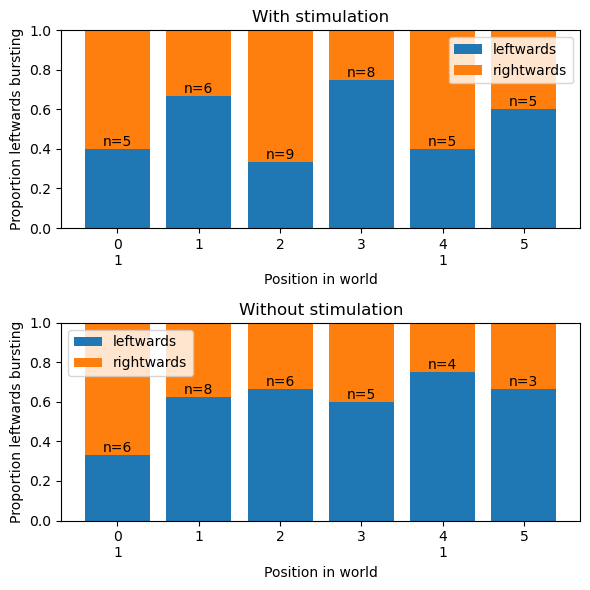

In [51]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
ax.bar(train_transition_df.index, train_transition_df["proportion left"], label = "leftwards")
ax.bar(train_transition_df.index, 1-train_transition_df["proportion left"], bottom = train_transition_df["proportion left"], label = "rightwards")
ax.bar_label(ax.containers[0], labels = [f"n={i:.0f}" for i in train_transition_df["total"]], label_type='edge')  # Annotating bars
plt.ylim(0, 1)
plt.ylabel("Proportion leftwards bursting")
plt.xlabel("Position in world")
plt.xticks(range(0, len(world)), [f"{i}\n{x}" if x != "0" else f"{i}" for i, x in enumerate(world)])
plt.legend()

ax = plt.subplot(212)
plt.title("Without stimulation")
ax.bar(pre_train_transition_df.index, pre_train_transition_df["proportion left"], label = "leftwards")
ax.bar(pre_train_transition_df.index, 1-pre_train_transition_df["proportion left"], bottom = pre_train_transition_df["proportion left"], label = "rightwards")

ax.bar_label(ax.containers[0], labels = [f"n={i:.0f}" for i in pre_train_transition_df["total"]], label_type = 'edge')  # Annotating bars
plt.ylim(0, 1)
plt.ylabel("Proportion leftwards bursting")
plt.xlabel("Position in world")
plt.ylim(0, 1)
plt.xticks(range(0, len(world)), [f"{i}\n{x}" if x != "0" else f"{i}" for i, x in enumerate(world)])
plt.legend()

plt.tight_layout()

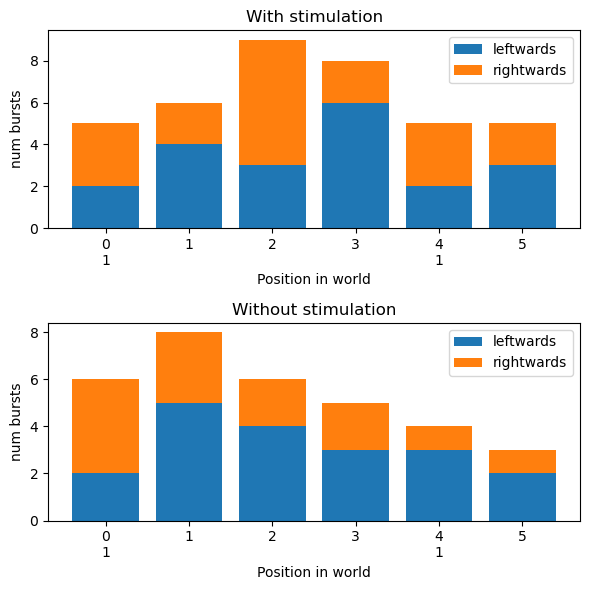

In [53]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
ax.bar(train_transition_df.index, train_transition_df["leftward"], label = "leftwards")
ax.bar(train_transition_df.index, train_transition_df["rightward"], bottom = train_transition_df["leftward"], label = "rightwards")
plt.ylabel("num bursts")
plt.xlabel("Position in world")
plt.xticks(range(0, len(world)), [f"{i}\n{x}" if x != "0" else f"{i}" for i, x in enumerate(world)])
ax.legend()

ax = plt.subplot(212)
plt.title("Without stimulation")
ax.bar(pre_train_transition_df.index, pre_train_transition_df["leftward"], label = "leftwards")
ax.bar(pre_train_transition_df.index, pre_train_transition_df["rightward"], bottom = pre_train_transition_df["leftward"], label = "rightwards")
plt.ylabel("num bursts")
plt.xlabel("Position in world")
plt.xticks(range(0, len(world)), [f"{i}\n{x}" if x != "0" else f"{i}" for i, x in enumerate(world)])
ax.legend()

plt.tight_layout()

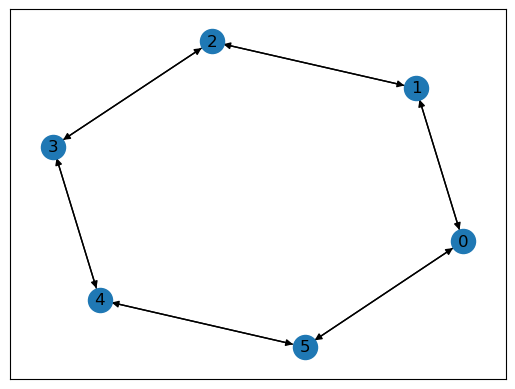

In [58]:
G = nx.DiGraph()
for i in range(len(world)):
    G.add_edge(i, (i+1)%len(world))
    G.add_edge((i+1)%len(world), i)

nx.draw_networkx(G)

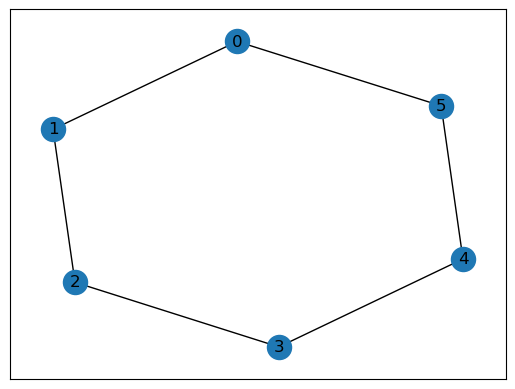

In [62]:
G = nx.cycle_graph(len(world))

nx.draw_networkx(G)